# wind power forecasting and turbine anomaly detection

two-pass xgboost forecast of hourly wind power, a 336-hour (2-week) forecast from analogue-bootstrapped weather, and isolation forest anomaly flags. built at rayfield systems (harvard undergraduate ventures tech).

**data note:** the original rayfield data is private. to run this notebook, use the similar public kaggle dataset [wind power generation data - forecasting](https://www.kaggle.com/datasets/mubashirrahim/wind-power-generation-data-forecasting) (4 locations, hourly, 2017-2021) as toy data.

## 0. setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

!pip install xgboost --quiet
import xgboost as xgb

import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

## 1. load data

In [ ]:
# toy data: point these paths at the 4 kaggle csvs (one per location)
loc1 = pd.read_csv("/content/drive/My Drive/Location1-rayfield.csv")
loc2 = pd.read_csv("/content/drive/My Drive/Location2-rayfield.csv")
loc3 = pd.read_csv("/content/drive/My Drive/Location3-rayfield.csv")
loc4 = pd.read_csv("/content/drive/My Drive/Location4-rayfield.csv")

## 2. location 1: explore

In [ ]:
loc1.describe()

,temperature_2m,relativehumidity_2m,dewpoint_2m,windspeed_10m,windspeed_100m,winddirection_10m,winddirection_100m,windgusts_10m,Power
count,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000
mean,47.862911,72.288744,38.569308,3.591147,6.284431,203.637329,203.343676,7.771795,0.405385
std,19.453691,16.852287,18.772110,1.649318,2.685216,96.371262,97.959852,3.569147,0.288322
min,-14.400000,18.000000,-17.100000,0.000000,0.100000,1.000000,0.000000,0.500000,0.000000
25%,32.100000,60.000000,24.300000,2.410000,4.380000,132.000000,130.000000,5.000000,0.148900
50%,47.300000,74.000000,38.100000,3.300000,6.080000,225.000000,226.000000,7.200000,0.347650
75%,64.500000,86.000000,54.700000,4.590000,7.990000,277.000000,278.000000,10.000000,0.659600
max,94.100000,100.000000,76.300000,13.450000,20.650000,360.000000,360.000000,29.200000,0.991300


In [ ]:
loc1

,Time,temperature_2m,relativehumidity_2m,dewpoint_2m,windspeed_10m,windspeed_100m,winddirection_10m,winddirection_100m,windgusts_10m,Power
0,2017-01-02 00:00:00,28.5,85,24.5,1.44,1.26,146,162,1.4,0.1635
1,2017-01-02 01:00:00,28.4,86,24.7,2.06,3.99,151,158,4.4,0.1424
2,2017-01-02 02:00:00,26.8,91,24.5,1.30,2.78,148,150,3.2,0.1214
3,2017-01-02 03:00:00,27.4,88,24.3,1.30,2.69,58,105,1.6,0.1003
4,2017-01-02 04:00:00,27.3,88,24.1,2.47,4.43,58,84,4.0,0.0793
...,...,...,...,...,...,...,...,...,...,...
43795,2021-12-31 19:00:00,34.1,94,32.5,1.00,1.91,53,137,2.5,0.1796
43796,2021-12-31 20:00:00,34.8,94,33.4,2.52,4.30,56,72,4.8,0.2066
43797,2021-12-31 21:00:00,34.1,95,33.0,1.10,1.84,360,45,4.3,0.2336
43798,2021-12-31 22:00:00,34.4,96,33.5,2.40,4.62,45,51,4.2,0.2606


In [ ]:
loc1['Time'] = pd.to_datetime(loc1['Time'])
loc1 = loc1.set_index('Time', drop=False)

In [ ]:
loc1

,Time,temperature_2m,relativehumidity_2m,dewpoint_2m,windspeed_10m,windspeed_100m,winddirection_10m,winddirection_100m,windgusts_10m,Power
Time,,,,,,,,,,
2017-01-02 00:00:00,2017-01-02 00:00:00,28.5,85,24.5,1.44,1.26,146,162,1.4,0.1635
2017-01-02 01:00:00,2017-01-02 01:00:00,28.4,86,24.7,2.06,3.99,151,158,4.4,0.1424
2017-01-02 02:00:00,2017-01-02 02:00:00,26.8,91,24.5,1.30,2.78,148,150,3.2,0.1214
2017-01-02 03:00:00,2017-01-02 03:00:00,27.4,88,24.3,1.30,2.69,58,105,1.6,0.1003
2017-01-02 04:00:00,2017-01-02 04:00:00,27.3,88,24.1,2.47,4.43,58,84,4.0,0.0793
...,...,...,...,...,...,...,...,...,...,...
2021-12-31 19:00:00,2021-12-31 19:00:00,34.1,94,32.5,1.00,1.91,53,137,2.5,0.1796
2021-12-31 20:00:00,2021-12-31 20:00:00,34.8,94,33.4,2.52,4.30,56,72,4.8,0.2066
2021-12-31 21:00:00,2021-12-31 21:00:00,34.1,95,33.0,1.10,1.84,360,45,4.3,0.2336


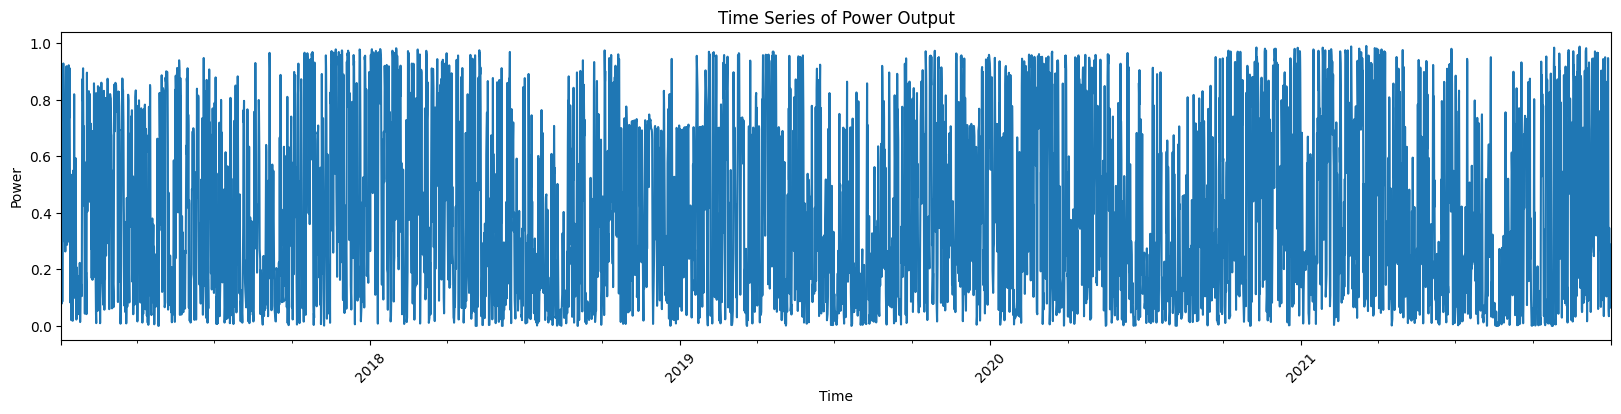

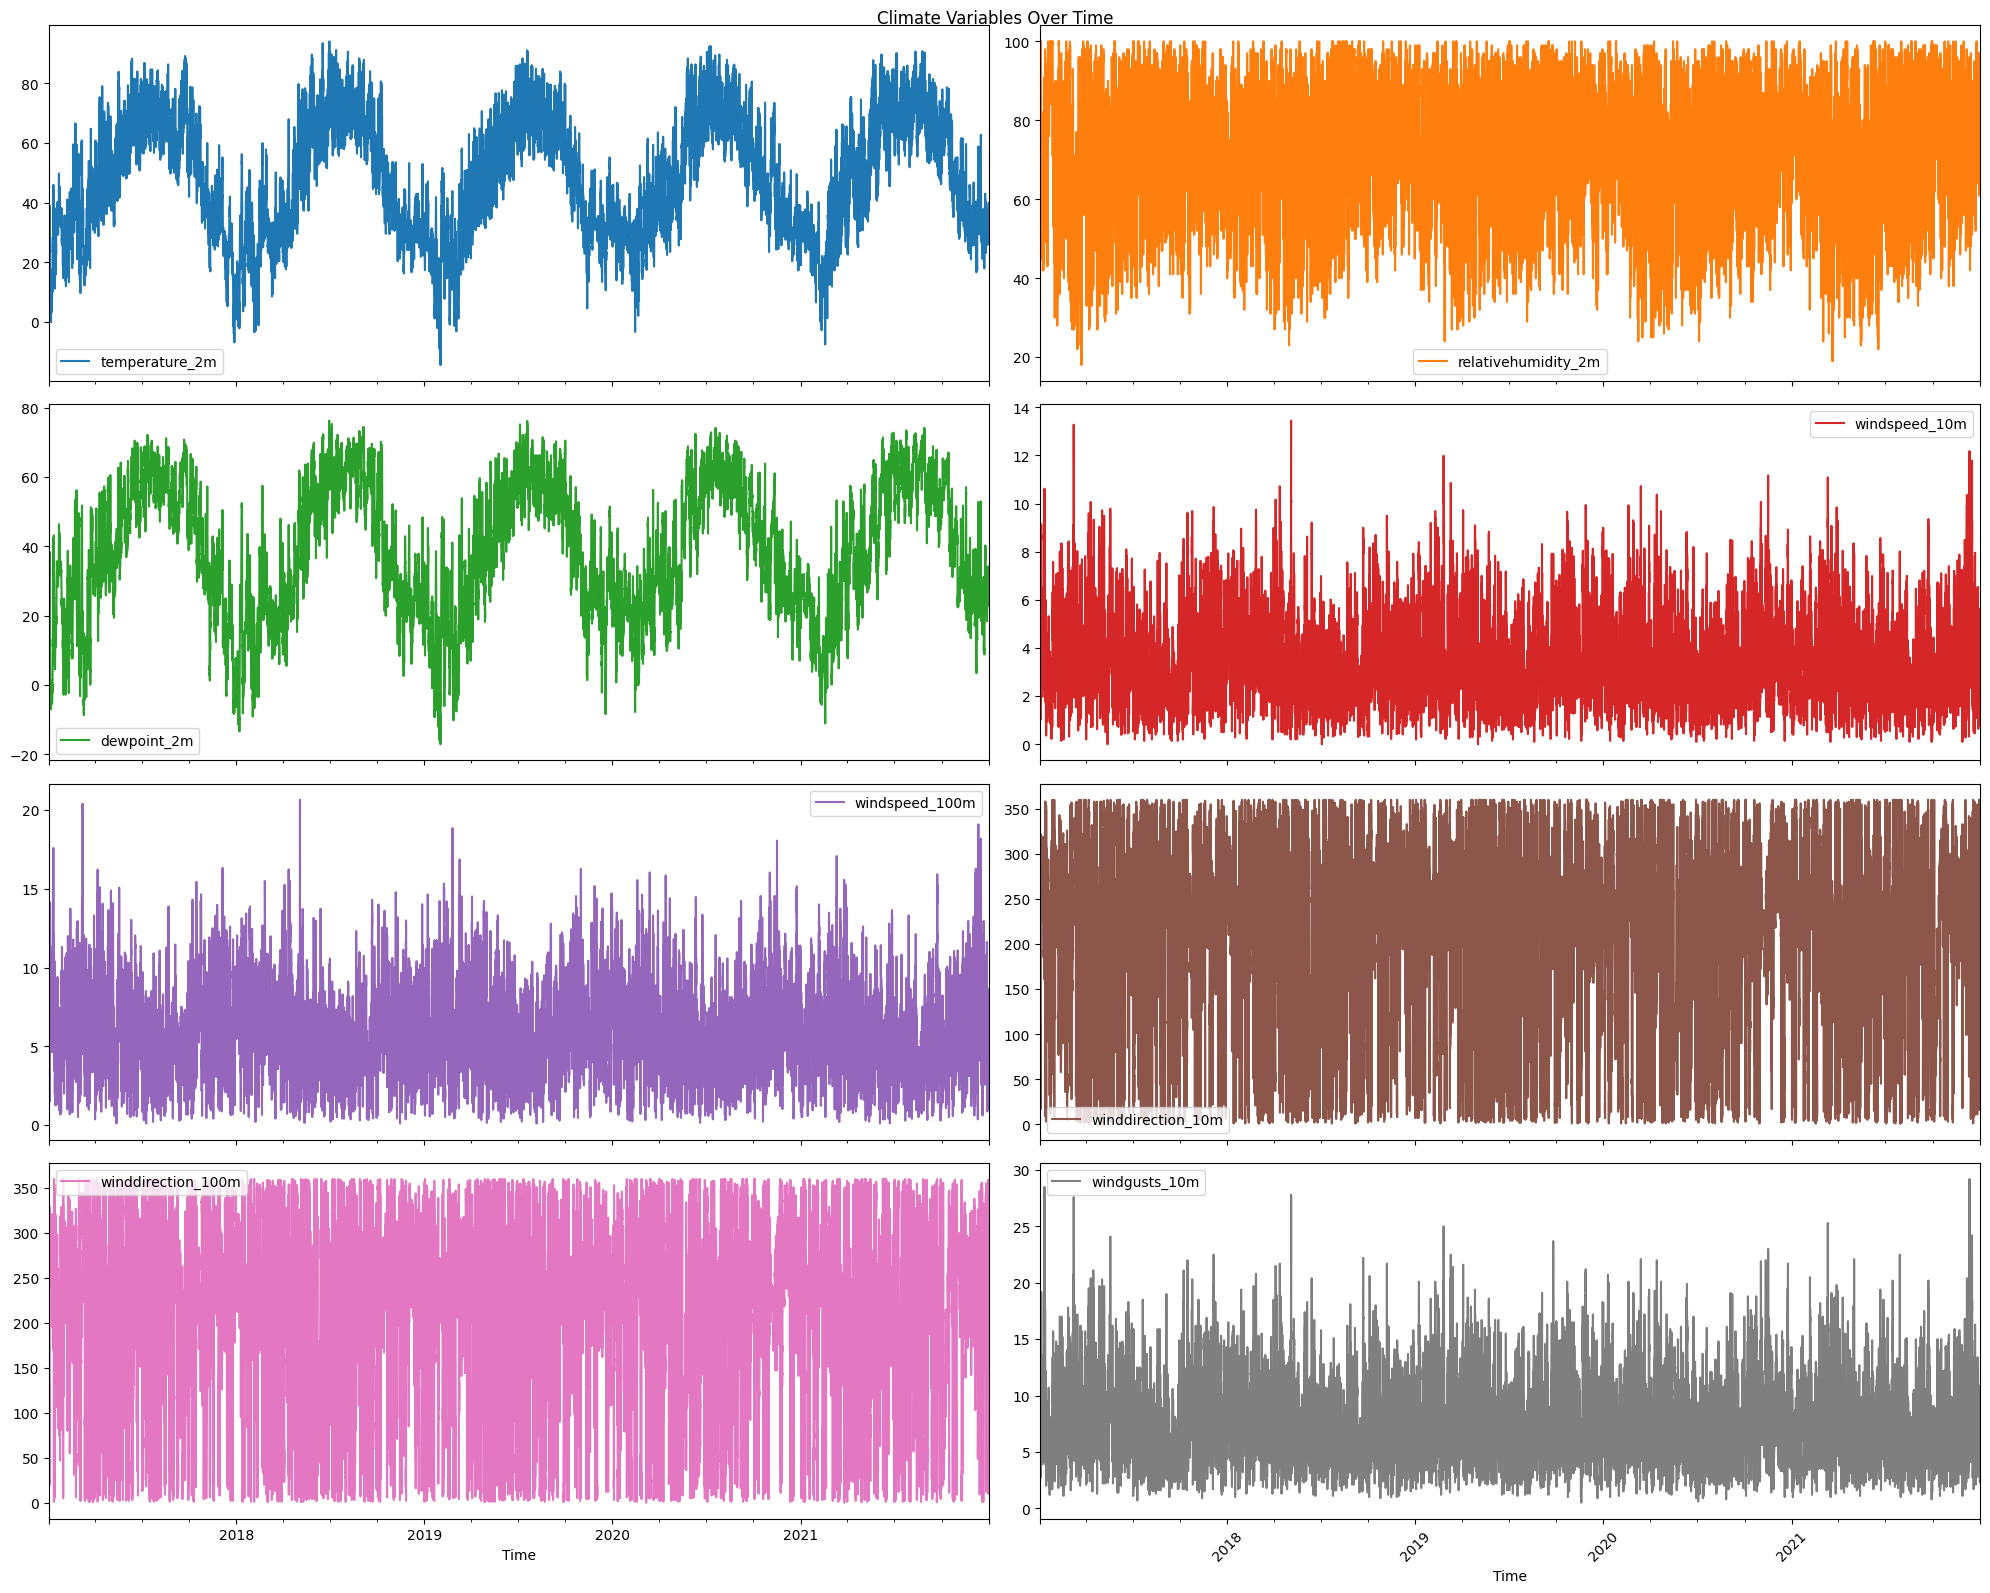

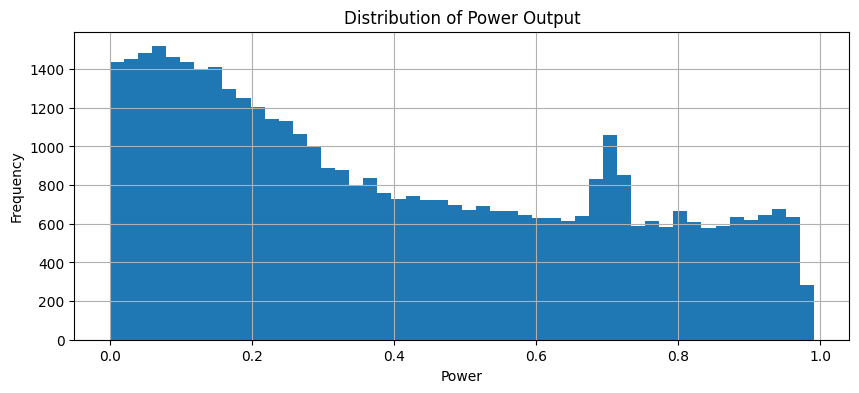

In [ ]:
loc1['Power'].plot(figsize=(20, 4), title='Time Series of Power Output')
plt.xlabel('Time')
plt.ylabel('Power')
plt.xticks(rotation=45)
plt.show()

climate_vars = ['temperature_2m', 'relativehumidity_2m', 'dewpoint_2m',
                'windspeed_10m', 'windspeed_100m', 'winddirection_10m',
                'winddirection_100m', 'windgusts_10m']

loc1[climate_vars].plot(subplots=True, figsize=(20, 16), layout=(4, 2), title='Climate Variables Over Time')
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

loc1['Power'].hist(bins=50, figsize=(10, 4))
plt.title('Distribution of Power Output')
plt.xlabel('Power')
plt.ylabel('Frequency')
plt.show()

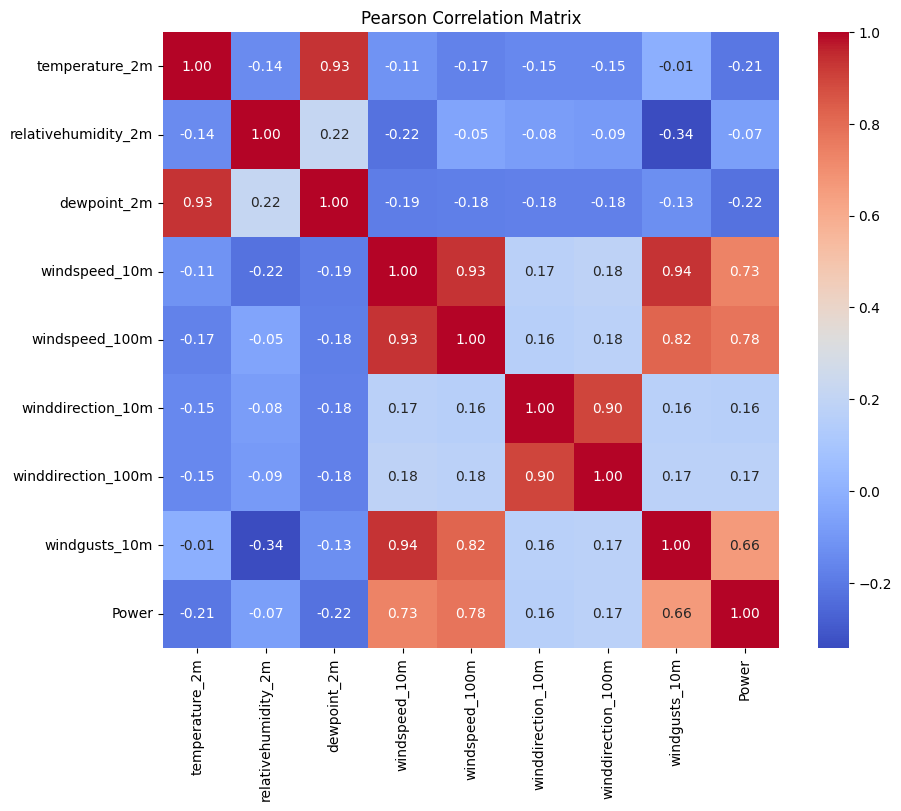

In [ ]:
corr_matrix = loc1.drop(columns='Time').corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Pearson Correlation Matrix')
plt.show()

## 3. location 1: feature engineering

In [ ]:
# keep one variable from each correlated group (see matrix above)
loc1 = loc1.drop(columns=['Time', 'relativehumidity_2m', 'dewpoint_2m', 'windspeed_10m', 'winddirection_10m'])
# encode hour of day as a circle so 23:00 sits next to 00:00
loc1['hour'] = loc1.index.hour
loc1['hour_sin'] = np.sin(2 * np.pi * loc1['hour'] / 24)
loc1['hour_cos'] = np.cos(2 * np.pi * loc1['hour'] / 24)
# 6-hour rolling power mean: the target for pass 1
loc1['rolling_6h_power_mean'] = loc1['Power'].rolling(window=6).mean()
loc1.drop(columns='hour', inplace=True)
loc1 = loc1.dropna(subset=['rolling_6h_power_mean'])
# power per unit of wind energy (wind speed cubed)
loc1['power_to_wind3'] = loc1['Power'] / (loc1['windspeed_100m'] ** 3)
loc1

,temperature_2m,windspeed_100m,winddirection_100m,windgusts_10m,Power,hour_sin,hour_cos,rolling_6h_power_mean,power_to_wind3
Time,,,,,,,,,
2017-01-02 05:00:00,27.6,5.59,80,4.5,0.0778,0.965926,2.588190e-01,0.114117,0.000445
2017-01-02 06:00:00,26.7,5.82,78,4.7,0.0959,1.000000,6.123234e-17,0.102850,0.000486
2017-01-02 07:00:00,28.4,6.24,78,4.8,0.1141,0.965926,-2.588190e-01,0.098133,0.000470
2017-01-02 08:00:00,30.2,6.89,81,5.8,0.1322,0.866025,-5.000000e-01,0.099933,0.000404
2017-01-02 09:00:00,34.0,6.01,86,6.5,0.1503,0.707107,-7.071068e-01,0.108267,0.000692
...,...,...,...,...,...,...,...,...,...
2021-12-31 19:00:00,34.1,1.91,137,2.5,0.1796,-0.965926,2.588190e-01,0.152800,0.025775
2021-12-31 20:00:00,34.8,4.30,72,4.8,0.2066,-0.866025,5.000000e-01,0.161983,0.002599
2021-12-31 21:00:00,34.1,1.84,45,4.3,0.2336,-0.707107,7.071068e-01,0.176267,0.037499


## 4. location 1: future weather via analogue bootstrap

In [ ]:
# find the past week whose weather best matches the most recent week, then use what followed it as future weather
def fast_analogue_bootstrap(loc1, features, window=168, forecast_horizon=168):
    current_block = loc1[features].iloc[-window:].copy()
    current_block = (current_block - current_block.mean()) / current_block.std()

    cutoff = len(loc1) - (window + forecast_horizon + 336)
    best_dist = float('inf')
    best_index = 0

    start_index = max(0, len(loc1) - 24*30*6)

    for i in range(start_index, cutoff, 12):
        past_block = loc1[features].iloc[i:i+window]
        if len(past_block) < window:
            continue
        past_block = (past_block - past_block.mean()) / past_block.std()
        dist = np.mean((current_block.values - past_block.values)**2)
        if dist < best_dist:
            best_dist = dist
            best_index = i

    future_index = pd.date_range(start=loc1.index[-1] + pd.Timedelta(hours=1), periods=forecast_horizon, freq='H')
    boot_forecast = loc1[features].iloc[best_index+window : best_index+window+forecast_horizon].copy()
    boot_forecast.index = future_index
    return boot_forecast

In [ ]:
features = ['temperature_2m', 'windspeed_100m', 'winddirection_100m', 'windgusts_10m', 'hour_sin', 'hour_cos']
future_df = fast_analogue_bootstrap(loc1, features, forecast_horizon=336)

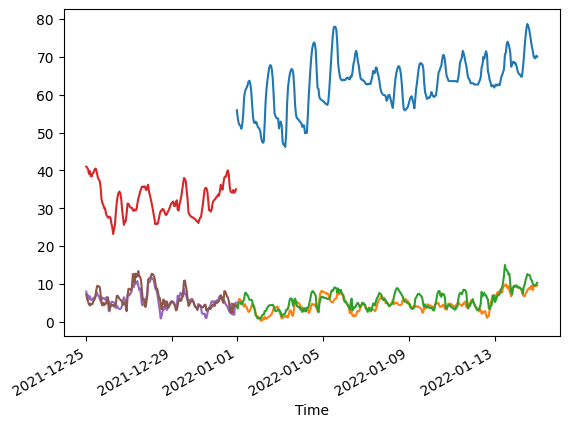

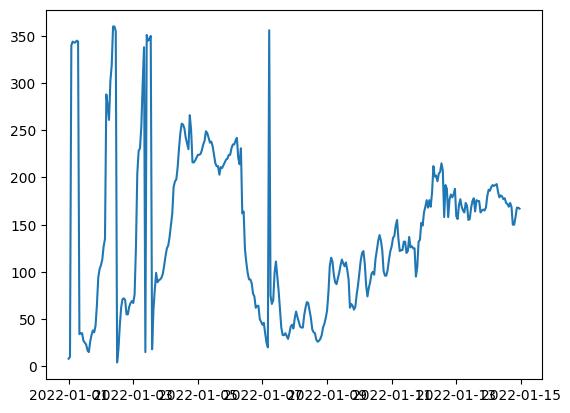

In [ ]:
plt.plot(future_df["temperature_2m"])
plt.plot(future_df["windspeed_100m"])
plt.plot(future_df["windgusts_10m"])

loc1["temperature_2m"][-168:].plot()
loc1["windspeed_100m"][-168:].plot()
loc1["windgusts_10m"][-168:].plot()

plt.show()
plt.plot(future_df["winddirection_100m"])
plt.show()

In [ ]:
def add_hour_sin_cos(df, time_col=None):
    if time_col:
        time_index = pd.to_datetime(df[time_col])
    else:
        time_index = pd.to_datetime(df.index)

    hour = time_index.hour
    df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    return df

In [ ]:
future_df = add_hour_sin_cos(future_df)
future_df

,temperature_2m,windspeed_100m,winddirection_100m,windgusts_10m,hour_sin,hour_cos
2022-01-01 00:00:00,55.9,4.54,8,4.1,0.000000,1.000000
2022-01-01 01:00:00,53.8,4.77,10,3.5,0.258819,0.965926
2022-01-01 02:00:00,52.5,5.85,340,5.0,0.500000,0.866025
2022-01-01 03:00:00,52.0,6.04,344,5.1,0.707107,0.707107
2022-01-01 04:00:00,51.8,5.76,343,5.2,0.866025,0.500000
...,...,...,...,...,...,...
2022-01-14 19:00:00,70.2,9.36,150,9.6,-0.965926,0.258819
2022-01-14 20:00:00,69.7,9.38,158,9.6,-0.866025,0.500000
2022-01-14 21:00:00,69.7,9.39,168,9.6,-0.707107,0.707107
2022-01-14 22:00:00,70.3,9.41,168,9.9,-0.500000,0.866025


## 5. location 1: two-pass model

pass 1 predicts the 6-hour rolling power mean from weather. pass 2 predicts hourly power from weather plus that rolling mean.

each pass is validated on its own here. pass 2's validation uses the actual historical rolling mean (which includes the hour being predicted), so it shows how well pass 2 works with ideal inputs, not how well the full forecast works. the end-to-end check below scores the real chain.

In [ ]:
def tolerance_accuracy(y_true, y_pred, tolerance = 0.1):
    return np.mean(np.abs(y_true - y_pred) <= tolerance)

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# pass 1: weather -> 6h rolling power mean
def train_pass1_model(df, n_iter=20, cv_splits=3):
    features = ['temperature_2m', 'windspeed_100m', 'winddirection_100m',
                'windgusts_10m', 'hour_sin', 'hour_cos']
    target = 'rolling_6h_power_mean'

    # chronological 80/20 split, no shuffling
    split = int(len(df) * 0.8)
    X_train, X_val = df[features].iloc[:split], df[features].iloc[split:]
    y_train, y_val = df[target].iloc[:split], df[target].iloc[split:]

    param_dist = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 4, 5, 6, 7],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'reg_alpha': [0, 0.1, 1],
        'reg_lambda': [1, 1.5, 2]
    }

    base_model = XGBRegressor(random_state=42, verbosity=0)
    tscv = TimeSeriesSplit(n_splits=cv_splits)

    search = RandomizedSearchCV(base_model, param_distributions=param_dist,
                                n_iter=n_iter, scoring='neg_root_mean_squared_error',
                                cv=tscv, random_state=42, verbose=0, n_jobs=-1)

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    preds = best_model.predict(X_val)
    rmse = mean_squared_error(y_val, preds) ** 0.5
    r2 = r2_score(y_val, preds)

    return {
        'model': best_model,
        'rmse': rmse,
        'r2': r2,
        'acc': tolerance_accuracy(y_val, preds),
        'best_params': search.best_params_
    }

In [ ]:
pass1_result = train_pass1_model(loc1)

In [ ]:
print(pass1_result)

{'model': XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=1.0, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...), 'rmse': 0.16912045238378665, 'r2': 0.6672328531557936, 'acc': np.float64(0.4562164630665601), 'best_params': {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 1.0}

In [ ]:
# pass 2: weather + rolling mean -> hourly power
def train_pass2_model(df, n_iter=20, cv_splits=3):
    features = ['temperature_2m', 'windspeed_100m', 'winddirection_100m',
                'windgusts_10m', 'hour_sin', 'hour_cos', 'rolling_6h_power_mean']
    target = 'Power'

    split = int(len(df) * 0.8)
    X_train, X_val = df[features].iloc[:split], df[features].iloc[split:]
    y_train, y_val = df[target].iloc[:split], df[target].iloc[split:]

    param_dist = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 4, 5, 6, 7],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'reg_alpha': [0, 0.1, 1],
        'reg_lambda': [1, 1.5, 2]
    }

    base_model = XGBRegressor(random_state=42, verbosity=0)
    tscv = TimeSeriesSplit(n_splits=cv_splits)

    search = RandomizedSearchCV(base_model, param_distributions=param_dist,
                                n_iter=n_iter, scoring='neg_root_mean_squared_error',
                                cv=tscv, random_state=42, verbose=0, n_jobs=-1)

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    preds = best_model.predict(X_val)
    rmse = mean_squared_error(y_val, preds) ** 0.5
    r2 = r2_score(y_val, preds)
    acc = tolerance_accuracy(y_val, preds, tolerance=0.10)

    return {
        'model': best_model,
        'rmse': rmse,
        'r2': r2,
        'acc': acc,
        'best_params': search.best_params_
    }

In [ ]:
pass2_result = train_pass2_model(loc1)

In [ ]:
pass2_result

{'model': XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...),
 'rmse': 0.07096692689612988,
 'r2': 0.9436516460943203,
 'acc': np.float64(0.8499828747573924),
 'best_params': {'subsample': 0.8,
  'reg_lambda': 1,
  'reg_alpha': 1,
  'n_estimators': 200,
  'max_depth': 4,
  'learning_rate': 0.05,


### end-to-end check: weather -> pass 1 -> pass 2, scored against actual power

In [ ]:
# same chain as the forecast, run on the historical validation weather
def evaluate_end_to_end(df, pass1_model, pass2_model):
    features_pass1 = ['temperature_2m', 'windspeed_100m', 'winddirection_100m',
                      'windgusts_10m', 'hour_sin', 'hour_cos']
    features_pass2 = features_pass1 + ['rolling_6h_power_mean']

    val = df.iloc[int(len(df) * 0.8):].copy()
    val['rolling_6h_power_mean'] = pass1_model.predict(val[features_pass1])
    preds = pass2_model.predict(val[features_pass2])
    y_val = val['Power']

    return {
        'rmse': mean_squared_error(y_val, preds) ** 0.5,
        'r2': r2_score(y_val, preds),
        'acc': tolerance_accuracy(y_val, preds, tolerance=0.10)
    }

In [ ]:
e2e_result = evaluate_end_to_end(loc1, pass1_result['model'], pass2_result['model'])
e2e_result

{'rmse': 0.15904805876013045,
 'r2': 0.7169742299913556,
 'acc': np.float64(0.49503367964379497)}

## 6. location 1: 336-hour forecast

In [ ]:
# chain the passes: the predicted rolling mean from pass 1 feeds pass 2
def predict_future_power(future_df, pass1_model, pass2_model):
    features_pass1 = ['temperature_2m', 'windspeed_100m', 'winddirection_100m',
                      'windgusts_10m', 'hour_sin', 'hour_cos']

    features_pass2 = features_pass1 + ['rolling_6h_power_mean']

    future_df['rolling_6h_power_mean'] = pass1_model.predict(future_df[features_pass1])
    future_df['predicted_power'] = pass2_model.predict(future_df[features_pass2])

    return future_df

In [ ]:
future_df = predict_future_power(future_df, pass1_result['model'], pass2_result['model'])

In [ ]:
future_df

,temperature_2m,windspeed_100m,winddirection_100m,windgusts_10m,hour_sin,hour_cos,rolling_6h_power_mean,predicted_power
2022-01-01 00:00:00,55.9,4.54,8,4.1,0.000000,1.000000,0.207944,0.203094
2022-01-01 01:00:00,53.8,4.77,10,3.5,0.258819,0.965926,0.215457,0.201270
2022-01-01 02:00:00,52.5,5.85,340,5.0,0.500000,0.866025,0.303917,0.302226
2022-01-01 03:00:00,52.0,6.04,344,5.1,0.707107,0.707107,0.331014,0.324583
2022-01-01 04:00:00,51.8,5.76,343,5.2,0.866025,0.500000,0.332045,0.312186
...,...,...,...,...,...,...,...,...
2022-01-14 19:00:00,70.2,9.36,150,9.6,-0.965926,0.258819,0.557751,0.650823
2022-01-14 20:00:00,69.7,9.38,158,9.6,-0.866025,0.500000,0.532053,0.617806
2022-01-14 21:00:00,69.7,9.39,168,9.6,-0.707107,0.707107,0.523521,0.614747
2022-01-14 22:00:00,70.3,9.41,168,9.9,-0.500000,0.866025,0.526997,0.615140


## 7. location 1: anomaly detection

In [ ]:
# physics-based features for spotting turbine faults
future_df["power_to_wind3"] = future_df["predicted_power"] / (future_df["windspeed_100m"] ** 3 + 1e-6)
future_df["deviation_from_rolling_mean"] = future_df["predicted_power"] - future_df["rolling_6h_power_mean"]
future_df["relative_power_drop"] = future_df["predicted_power"].diff() / (future_df["predicted_power"].shift(1) + 1e-6)
future_df["gustiness"] = future_df["windgusts_10m"] / (future_df["windspeed_100m"] + 1e-6)
future_df

,temperature_2m,windspeed_100m,winddirection_100m,windgusts_10m,hour_sin,hour_cos,rolling_6h_power_mean,predicted_power,power_to_wind3,deviation_from_rolling_mean,relative_power_drop,gustiness
2022-01-01 00:00:00,55.9,4.54,8,4.1,0.000000,1.000000,0.207944,0.203094,0.002170,-0.004851,NaN,0.903084
2022-01-01 01:00:00,53.8,4.77,10,3.5,0.258819,0.965926,0.215457,0.201270,0.001854,-0.014186,-0.008978,0.733752
2022-01-01 02:00:00,52.5,5.85,340,5.0,0.500000,0.866025,0.303917,0.302226,0.001510,-0.001691,0.501588,0.854701
2022-01-01 03:00:00,52.0,6.04,344,5.1,0.707107,0.707107,0.331014,0.324583,0.001473,-0.006431,0.073976,0.844371
2022-01-01 04:00:00,51.8,5.76,343,5.2,0.866025,0.500000,0.332045,0.312186,0.001634,-0.019859,-0.038195,0.902778
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-01-14 19:00:00,70.2,9.36,150,9.6,-0.965926,0.258819,0.557751,0.650823,0.000794,0.093072,0.013049,1.025641
2022-01-14 20:00:00,69.7,9.38,158,9.6,-0.866025,0.500000,0.532053,0.617806,0.000749,0.085753,-0.050731,1.023454
2022-01-14 21:00:00,69.7,9.39,168,9.6,-0.707107,0.707107,0.523521,0.614747,0.000743,0.091227,-0.004951,1.022364
2022-01-14 22:00:00,70.3,9.41,168,9.9,-0.500000,0.866025,0.526997,0.615140,0.000738,0.088143,0.000639,1.052072


In [ ]:
future_df["relative_power_drop"] = future_df["relative_power_drop"].fillna(0)

In [ ]:
from sklearn.ensemble import IsolationForest

# flag the most unusual 10% of forecast hours
def detect_anomalies_with_isolation_forest(future_df, contamination=0.1):
    features = ["power_to_wind3", "deviation_from_rolling_mean", "relative_power_drop", "gustiness"]
    X = future_df[features].copy()
    X = X.fillna(0)

    model = IsolationForest(n_estimators=100, contamination=contamination, random_state=42)
    model.fit(X)

    future_df["anomaly_score"] = model.decision_function(X)
    future_df["anomaly_flag"] = model.predict(X)
    future_df["anomaly_flag"] = (future_df["anomaly_flag"] == -1).astype(int)

    return future_df, model

In [ ]:
future_df, model = detect_anomalies_with_isolation_forest(future_df, contamination=0.1)

In [ ]:
future_df

,temperature_2m,windspeed_100m,winddirection_100m,windgusts_10m,hour_sin,hour_cos,rolling_6h_power_mean,predicted_power,power_to_wind3,deviation_from_rolling_mean,relative_power_drop,gustiness,anomaly_score,anomaly_flag
2022-01-01 00:00:00,55.9,4.54,8,4.1,0.000000,1.000000,0.207944,0.203094,0.002170,-0.004851,0.000000,0.903084,0.136610,0
2022-01-01 01:00:00,53.8,4.77,10,3.5,0.258819,0.965926,0.215457,0.201270,0.001854,-0.014186,-0.008978,0.733752,0.108269,0
2022-01-01 02:00:00,52.5,5.85,340,5.0,0.500000,0.866025,0.303917,0.302226,0.001510,-0.001691,0.501588,0.854701,0.059097,0
2022-01-01 03:00:00,52.0,6.04,344,5.1,0.707107,0.707107,0.331014,0.324583,0.001473,-0.006431,0.073976,0.844371,0.135461,0
2022-01-01 04:00:00,51.8,5.76,343,5.2,0.866025,0.500000,0.332045,0.312186,0.001634,-0.019859,-0.038195,0.902778,0.116945,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-01-14 19:00:00,70.2,9.36,150,9.6,-0.965926,0.258819,0.557751,0.650823,0.000794,0.093072,0.013049,1.025641,0.039875,0
2022-01-14 20:00:00,69.7,9.38,158,9.6,-0.866025,0.500000,0.532053,0.617806,0.000749,0.085753,-0.050731,1.023454,0.042426,0
2022-01-14 21:00:00,69.7,9.39,168,9.6,-0.707107,0.707107,0.523521,0.614747,0.000743,0.091227,-0.004951,1.022364,0.046076,0
2022-01-14 22:00:00,70.3,9.41,168,9.9,-0.500000,0.866025,0.526997,0.615140,0.000738,0.088143,0.000639,1.052072,0.045456,0


## 8. location 1: results and feature importance

In [ ]:
import matplotlib.pyplot as plt

def plot_actual_vs_predicted_with_anomalies(loc1, future_df, model, back_hours=168):
    total_len = len(loc1)
    val_start = int(total_len * 0.8)

    val_index_range = total_len - val_start
    if back_hours > val_index_range:
        print("Range too large, exceeds validation size (aim for 20% of total historical data).")
        return

    features = ['temperature_2m', 'windspeed_100m', 'winddirection_100m',
                'windgusts_10m', 'hour_sin', 'hour_cos', 'rolling_6h_power_mean']

    loc1_val = loc1.iloc[val_start:]
    X_val = loc1_val[features]
    y_val = loc1_val['Power']
    preds_val = model.predict(X_val)

    actual_slice = y_val.iloc[-back_hours:]
    pred_slice = preds_val[-back_hours:]
    time_slice = actual_slice.index

    future_pred = future_df['predicted_power']
    future_time = future_df.index

    anomaly_mask = future_df["anomaly_flag"] == 1
    anomaly_times = future_df.index[anomaly_mask]
    anomaly_values = future_df["predicted_power"][anomaly_mask]

    plt.figure(figsize=(14, 4))
    plt.plot(time_slice, actual_slice, label='Actual Power', color='black')
    plt.plot(time_slice, pred_slice, label='Predicted Power (Validation)', color='blue')
    plt.plot(future_time, future_pred, label='Forecasted Power (Future)', color='green', linestyle='--')

    plt.scatter(anomaly_times, anomaly_values, color='red', label='Anomalies')

    for i, (t, v) in enumerate(zip(anomaly_times, anomaly_values)):
        if i % 3 == 0:
            offset = 8 if i % 6 == 0 else -12
            plt.annotate(f"{v:.2f}", (t, v), textcoords="offset points", xytext=(0, offset), ha='center', fontsize=8, color='red')

    plt.legend()
    plt.title('Power Output: Actual vs Predicted vs Forecast')
    plt.xlabel('Time')
    plt.ylabel('Power')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


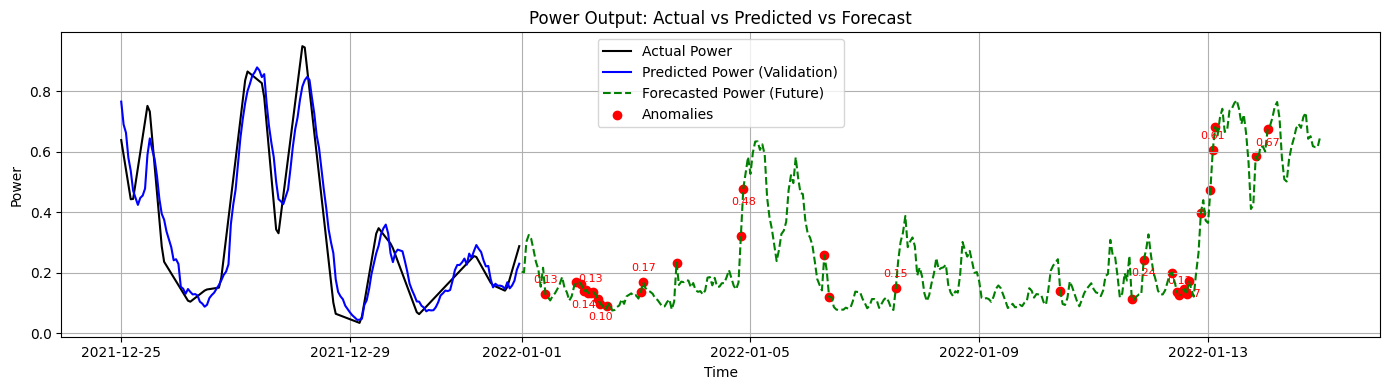

In [ ]:
plot_actual_vs_predicted_with_anomalies(loc1, future_df, pass2_result['model'], back_hours=168)

In [ ]:
pass1_model = pass1_result['model']

<Figure size 800x600 with 0 Axes>

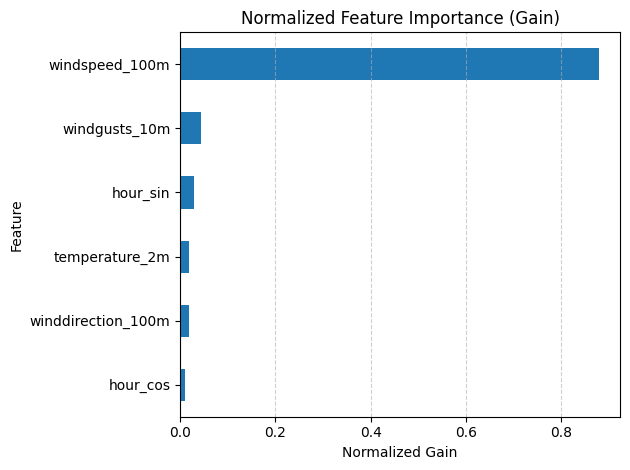

In [ ]:
booster = pass1_model.get_booster()
importance_dict = booster.get_score(importance_type='gain')

importance_df = pd.DataFrame.from_dict(importance_dict, orient='index', columns=['Gain'])
importance_df['Gain'] = importance_df['Gain'] / importance_df['Gain'].sum()
importance_df = importance_df.sort_values('Gain', ascending=True)

plt.figure(figsize=(8, 6))
importance_df.plot(kind='barh', legend=False)
plt.title('Normalized Feature Importance (Gain)')
plt.xlabel('Normalized Gain')
plt.ylabel('Feature')
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

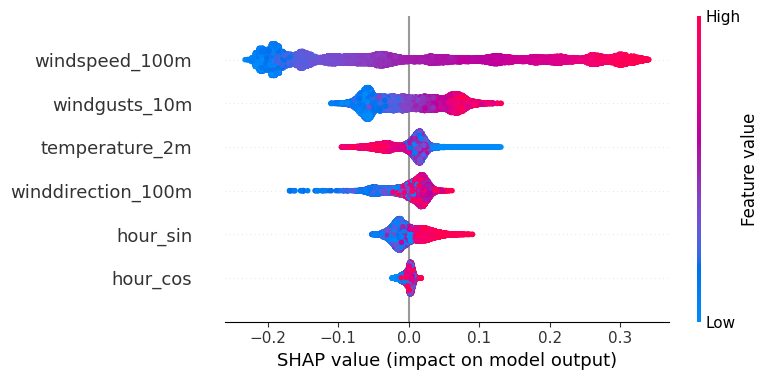

In [ ]:
import shap

X = loc1[['temperature_2m', 'windspeed_100m', 'winddirection_100m',
                'windgusts_10m', 'hour_sin', 'hour_cos']]

explainer = shap.TreeExplainer(pass1_model)
shap_values = explainer.shap_values(X)

shap.summary_plot(shap_values, X)

## 9. generalization: locations 2-4

same pipeline, same settings, applied to the other three locations.

In [ ]:
def prep_location(df):
    df = df.copy()
    df['Time'] = pd.to_datetime(df['Time'])
    df = df.set_index('Time', drop=False)
    df = df.drop(columns=['Time', 'relativehumidity_2m', 'dewpoint_2m', 'windspeed_10m', 'winddirection_10m'])
    df['hour'] = df.index.hour
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    df['rolling_6h_power_mean'] = df['Power'].rolling(window=6).mean()
    df.drop(columns='hour', inplace=True)
    df = df.dropna(subset=['rolling_6h_power_mean'])
    df['power_to_wind3'] = df['Power'] / (df['windspeed_100m'] ** 3)
    return df

In [ ]:
bootstrap_features = ['temperature_2m', 'windspeed_100m', 'winddirection_100m', 'windgusts_10m', 'hour_sin', 'hour_cos']

prepped = {'loc1': loc1}
results = {'loc1': {'pass1': pass1_result, 'pass2': pass2_result, 'e2e': e2e_result}}
forecasts = {'loc1': future_df}

for name, raw in {'loc2': loc2, 'loc3': loc3, 'loc4': loc4}.items():
    df = prep_location(raw)
    p1 = train_pass1_model(df)
    p2 = train_pass2_model(df)

    fut = fast_analogue_bootstrap(df, bootstrap_features, forecast_horizon=336)
    fut = add_hour_sin_cos(fut)
    fut = predict_future_power(fut, p1['model'], p2['model'])

    fut["power_to_wind3"] = fut["predicted_power"] / (fut["windspeed_100m"] ** 3 + 1e-6)
    fut["deviation_from_rolling_mean"] = fut["predicted_power"] - fut["rolling_6h_power_mean"]
    fut["relative_power_drop"] = fut["predicted_power"].diff() / (fut["predicted_power"].shift(1) + 1e-6)
    fut["relative_power_drop"] = fut["relative_power_drop"].fillna(0)
    fut["gustiness"] = fut["windgusts_10m"] / (fut["windspeed_100m"] + 1e-6)
    fut, _ = detect_anomalies_with_isolation_forest(fut, contamination=0.1)

    prepped[name] = df
    results[name] = {'pass1': p1, 'pass2': p2, 'e2e': evaluate_end_to_end(df, p1['model'], p2['model'])}
    forecasts[name] = fut

loc2


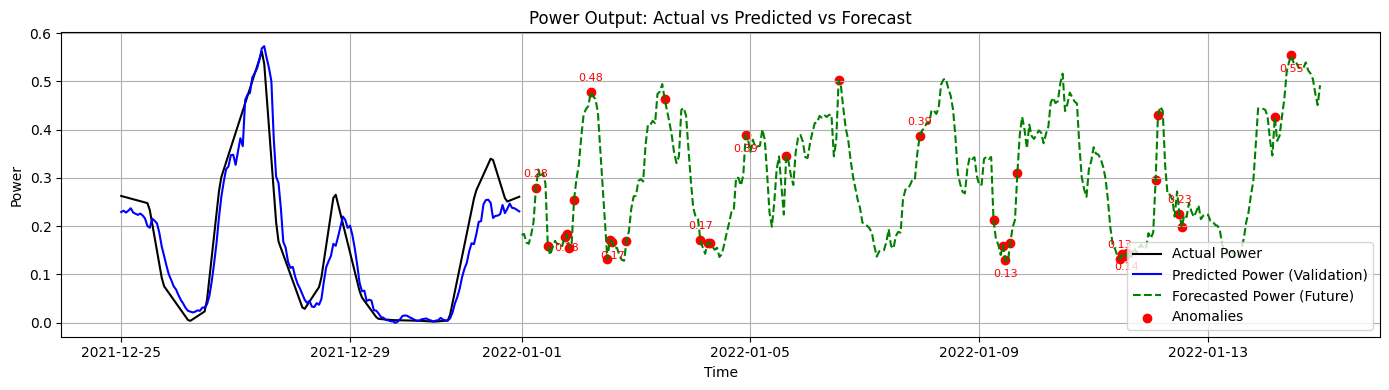

loc3


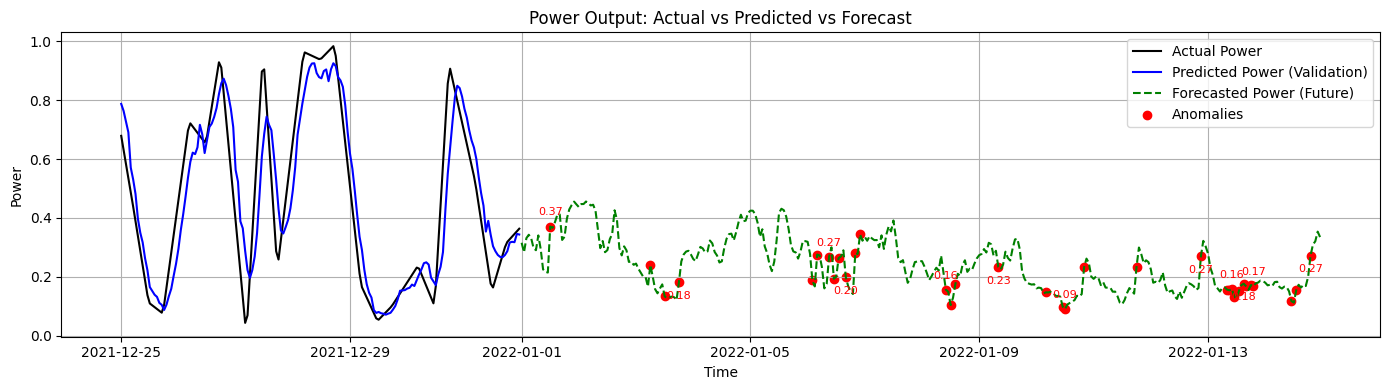

loc4


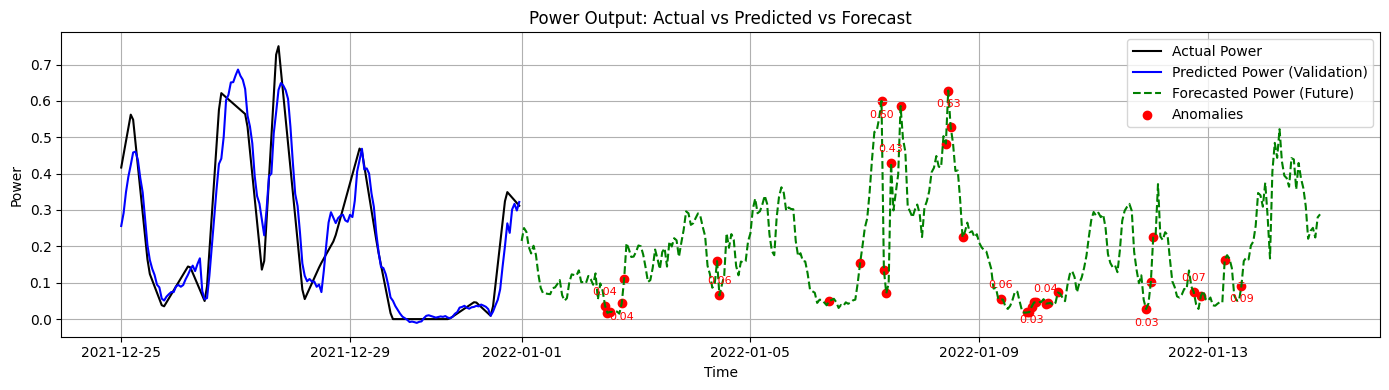

In [ ]:
for name in ['loc2', 'loc3', 'loc4']:
    print(name)
    plot_actual_vs_predicted_with_anomalies(prepped[name], forecasts[name], results[name]['pass2']['model'], back_hours=168)

## 10. summary across locations

In [ ]:
summary = pd.DataFrame({
    name: {
        'pass1_rmse': r['pass1']['rmse'],
        'pass1_r2': r['pass1']['r2'],
        'pass1_acc_0.10': r['pass1']['acc'],
        'pass2_rmse': r['pass2']['rmse'],
        'pass2_r2': r['pass2']['r2'],
        'pass2_acc_0.10': r['pass2']['acc'],
        'e2e_rmse': r['e2e']['rmse'],
        'e2e_r2': r['e2e']['r2'],
        'e2e_acc_0.10': r['e2e']['acc'],
        'anomalies_flagged': int(forecasts[name]['anomaly_flag'].sum()),
    }
    for name, r in results.items()
}).T.round(3)
summary

,pass1_rmse,pass1_r2,pass1_acc_0.10,pass2_rmse,pass2_r2,pass2_acc_0.10,e2e_rmse,e2e_r2,e2e_acc_0.10,anomalies_flagged
loc1,0.169,0.667,0.456,0.071,0.944,0.850,0.159,0.717,0.495,34.0
loc2,0.166,0.087,0.402,0.060,0.887,0.903,0.168,0.123,0.430,34.0
loc3,0.275,0.108,0.196,0.069,0.945,0.869,0.278,0.116,0.211,34.0
loc4,0.122,0.695,0.678,0.056,0.939,0.920,0.115,0.741,0.701,34.0


## 11. diagnosis: why locations 2 and 3 underperform

pass 1 drives the end-to-end score, so the question is why weather explains power well at locations 1 and 4 but not at 2 and 3. these cells check for a shift between the train and validation periods (curtailment, downtime, or a flat validation period).

In [ ]:
diag_rows = []
for name, df in prepped.items():
    split = int(len(df) * 0.8)
    train, val = df.iloc[:split], df.iloc[split:]
    high_wind = train['windspeed_100m'].quantile(0.75)
    diag_rows.append({
        'location': name,
        'val_start': val.index[0].date(),
        'power_std_train': train['Power'].std(),
        'power_std_val': val['Power'].std(),
        'corr_wind_power_train': train['Power'].corr(train['windspeed_100m']),
        'corr_wind_power_val': val['Power'].corr(val['windspeed_100m']),
        'low_power_high_wind_train': ((train['Power'] < 0.02) & (train['windspeed_100m'] > high_wind)).mean(),
        'low_power_high_wind_val': ((val['Power'] < 0.02) & (val['windspeed_100m'] > high_wind)).mean(),
    })
pd.DataFrame(diag_rows).set_index('location').round(3)

,val_start,power_std_train,power_std_val,corr_wind_power_train,corr_wind_power_val,low_power_high_wind_train,low_power_high_wind_val
location,,,,,,,
loc1,2021-01-01,0.286,0.299,0.777,0.788,0.001,0.000
loc2,2021-01-01,0.213,0.180,0.653,0.529,0.004,0.024
loc3,2021-01-01,0.253,0.296,0.605,0.409,0.025,0.079
loc4,2021-01-01,0.229,0.226,0.823,0.800,0.001,0.001


In [ ]:
yearly_corr = pd.DataFrame({
    name: df.groupby(df.index.year).apply(lambda g: g['Power'].corr(g['windspeed_100m']))
    for name, df in prepped.items()
}).round(3)
yearly_corr

,loc1,loc2,loc3,loc4
Time,,,,
2017,0.783,0.720,0.706,0.812
2018,0.746,0.720,0.726,0.811
2019,0.787,0.727,0.708,0.823
2020,0.794,0.613,0.346,0.842
2021,0.788,0.529,0.409,0.800


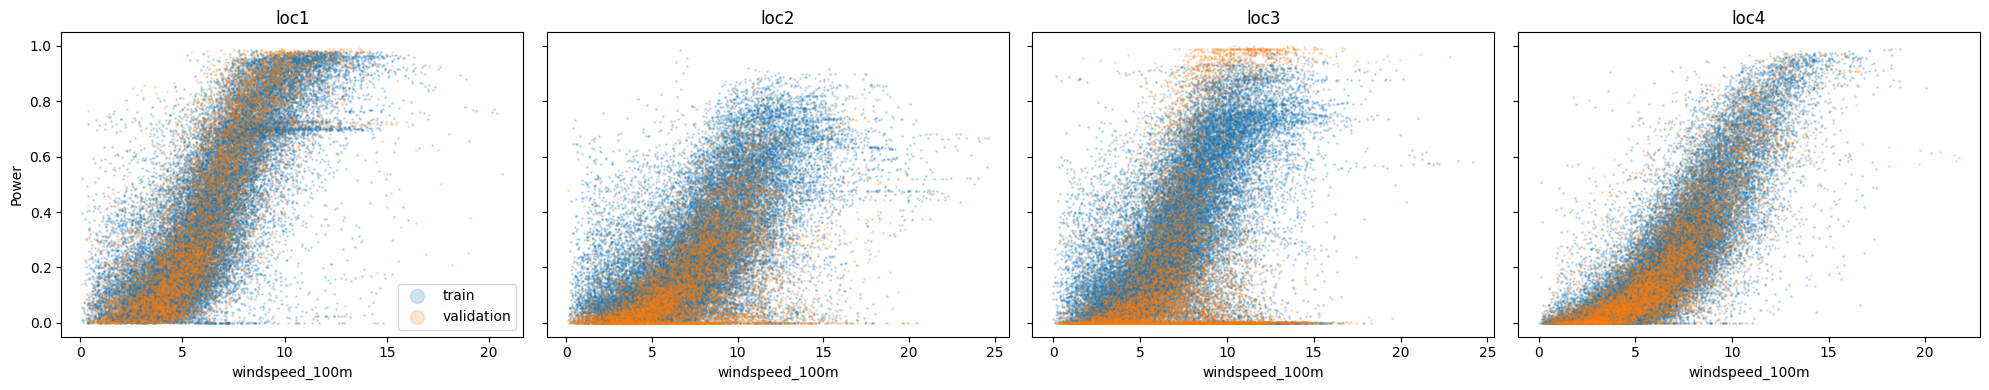

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, (name, df) in zip(axes, prepped.items()):
    split = int(len(df) * 0.8)
    ax.scatter(df['windspeed_100m'].iloc[:split], df['Power'].iloc[:split], s=1, alpha=0.2, label='train')
    ax.scatter(df['windspeed_100m'].iloc[split:], df['Power'].iloc[split:], s=1, alpha=0.2, label='validation')
    ax.set_title(name)
    ax.set_xlabel('windspeed_100m')
axes[0].set_ylabel('Power')
axes[0].legend(markerscale=10)
plt.tight_layout()
plt.show()

**findings:** the model isn't inherently worse at locations 2 and 3, because the sites and data-reporting changed structurally.

- the wind-power correlation was stable from 2017 to 2019 at every site (0.71-0.82). then it dropped at location 2 (0.61 in 2020, 0.53 in 2021) and collapsed at location 3 (0.35 in 2020, 0.41 in 2021). locations 1 and 4 stayed stable.
- hours with near-zero power despite high wind went from 0.4% (train) to 2.4% (validation) at location 2, and from 2.5% to 7.9% at location 3. that's the signature of downtime or curtailment.
- location 3's validation data also follows a different power curve: it reaches ~1.0 at 10-14 m/s, where training plateaued near ~0.75. that looks like an equipment or capacity change. location 2's validation output rarely goes above ~0.6, which is consistent with derating.
- weather can't predict outages or a new power curve, so pass 1 (and the end-to-end chain) fails exactly where the sites changed. where the relationship held (locations 1 and 4), the weather-only forecast scores r² 0.72-0.74.

**next steps:** filter non-operating hours (near-zero power above cut-in wind) before training and scoring, retrain location 3 on post-change data only, and run the anomaly detector on observed data, where these outage hours are exactly the anomalies worth flagging.